**The training set contained 69,777 records and the test set contained 17,445 records. Both sets had the same cancellation rate of 27.53% because a stratified split was used**


In [1]:
# 1. SETUP


from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    RocCurveDisplay
)

RANDOM_STATE = 42

ROOT = Path('/content/drive/MyDrive/hotel-booking-cancellation')

SPLIT_DIR = ROOT / 'data/splits'
MODEL_DIR = ROOT / 'models'
REPORT_DIR = ROOT / 'reports/member2_decision_tree'

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Setup completed.")

Mounted at /content/drive
Setup completed.


STEP 2 — Load the shared train/test data

In [2]:

X_train = pd.read_csv(
    SPLIT_DIR / 'X_train.csv',
    dtype={'agent': str}
)

X_test = pd.read_csv(
    SPLIT_DIR / 'X_test.csv',
    dtype={'agent': str}
)

y_train = pd.read_csv(
    SPLIT_DIR / 'y_train.csv'
)['is_canceled']

y_test = pd.read_csv(
    SPLIT_DIR / 'y_test.csv'
)['is_canceled']

shared_preprocessor = joblib.load(
    MODEL_DIR / 'preprocessor_unfitted.joblib'
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining cancellation rate:",
      round(y_train.mean() * 100, 2), "%")

print("Testing cancellation rate:",
      round(y_test.mean() * 100, 2), "%")

X_train: (69777, 28)
X_test : (17445, 28)
y_train: (69777,)
y_test : (17445,)

Training cancellation rate: 27.53 %
Testing cancellation rate: 27.53 %


## **STEP 3 — Build the baseline Decision Tree**

In [3]:

# 3. BASELINE DECISION TREE


baseline_tree = DecisionTreeClassifier(
    random_state=RANDOM_STATE
)

baseline_pipeline = Pipeline([
    ('preprocess', clone(shared_preprocessor)),
    ('model', baseline_tree)
])

baseline_pipeline.fit(X_train, y_train)

print("Baseline Decision Tree trained successfully.")

Baseline Decision Tree trained successfully.


1st trained baseline decision tree without restricting tree depth

# **STEP 4 — Make predictions**

In [5]:
# ============================================================
# 4. BASELINE PREDICTIONS
# ============================================================

y_train_pred = baseline_pipeline.predict(X_train)
y_test_pred = baseline_pipeline.predict(X_test)

y_test_prob = baseline_pipeline.predict_proba(X_test)[:, 1]

# **STEP 5 — Calculate evaluation metrics**


- Accuracy
- Precision
- Recall
- F1
- ROC-AUC


In [6]:
# 5. BASELINE MODEL EVALUATION


baseline_accuracy = accuracy_score(y_test, y_test_pred)
baseline_precision = precision_score(y_test, y_test_pred)
baseline_recall = recall_score(y_test, y_test_pred)
baseline_f1 = f1_score(y_test, y_test_pred)
baseline_roc_auc = roc_auc_score(y_test, y_test_prob)

print("BASELINE DECISION TREE RESULTS")
print("=" * 45)

print(f"Accuracy : {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall   : {baseline_recall:.4f}")
print(f"F1-score : {baseline_f1:.4f}")
print(f"ROC-AUC  : {baseline_roc_auc:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=['Not Cancelled', 'Cancelled']
))

BASELINE DECISION TREE RESULTS
Accuracy : 0.7983
Precision: 0.6336
Recall   : 0.6341
F1-score : 0.6338
ROC-AUC  : 0.7491

Classification Report:
               precision    recall  f1-score   support

Not Cancelled       0.86      0.86      0.86     12643
    Cancelled       0.63      0.63      0.63      4802

     accuracy                           0.80     17445
    macro avg       0.75      0.75      0.75     17445
 weighted avg       0.80      0.80      0.80     17445



# **STEP 6 — Confusion Matrix**

creates the confusion matrix for the baseline Decision Tree. It shows how many predictions were correct and incorrect by separating them into true negatives, false positives, false negatives, and true positives

Confusion Matrix:
[[10882  1761]
 [ 1757  3045]]


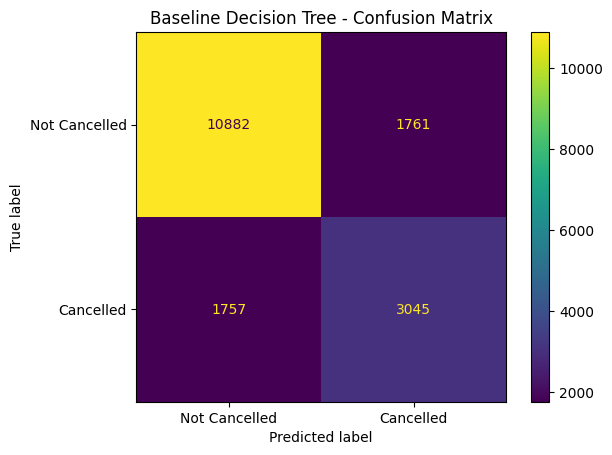

In [7]:

# 6. CONFUSION MATRIX


cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Cancelled', 'Cancelled']
)

disp.plot()
plt.title("Baseline Decision Tree - Confusion Matrix")
plt.show()

TN – True Negative
Not cancelled → correctly predicted not cancelled.

TP – True Positive
Cancelled → correctly predicted cancelled.

FP – False Positive
Actually didn't cancel, but model predicted cancellation.

FN – False Negative
Actually cancelled, but model predicted no cancellation.

For your hotel problem, false negatives are particularly useful to watch, because they represent cancellations the hotel model failed to identify.

# **STEP 7 — ROC Curve**

plots the ROC curve using the predicted cancellation probabilities. It shows how well the model can distinguish cancelled bookings from non-cancelled bookings across different classification thresholds.


How well can the model separate the two classes

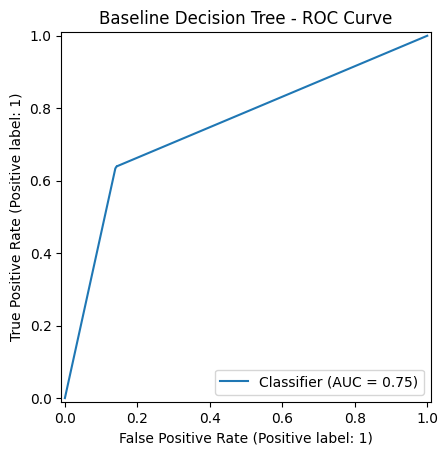

In [8]:

# 7. ROC CURVE


RocCurveDisplay.from_predictions(
    y_test,
    y_test_prob
)

plt.title("Baseline Decision Tree - ROC Curve")
plt.show()



Cancelled vs Not Cancelled
The main number associated with it is ROC-AUC.
baseline:
0.7491
After tuning:
0.8839

The ROC-AUC improved from 0.7491 in the baseline model to 0.8839 after tuning, indicating that the tuned Decision Tree had better ability to distinguish cancelled from non-cancelled bookings.

STEP 8 — : Overfitting **analysis**

In [9]:

# 8. OVERFITTING ANALYSIS


train_accuracy = accuracy_score(
    y_train,
    y_train_pred
)

test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

print("Train Accuracy:", round(train_accuracy, 4))
print("Test Accuracy :", round(test_accuracy, 4))

print("Accuracy Gap  :",
      round(train_accuracy - test_accuracy, 4))

Train Accuracy: 0.9969
Test Accuracy : 0.7983
Accuracy Gap  : 0.1985


STEP 9 — Check tree complexity of baseline

In [10]:

# 9. TREE COMPLEXITY


tree_model = baseline_pipeline.named_steps['model']

print("Tree depth:",
      tree_model.get_depth())

print("Number of leaves:",
      tree_model.get_n_leaves())

Tree depth: 47
Number of leaves: 9781


# **STEP 10 — Tune the Decision Tree**

to reduce oerfitting used gribsearchcv with 5 fold cross validation to tune decision tree hypermeters


The best combination was Gini criterion, max depth 15, minimum samples leaf 1, and minimum samples split 20. The best cross-validation F1-score was 0.6742

In [11]:


# 10. DECISION TREE HYPERPARAMETER TUNING


tuning_pipeline = Pipeline([
    ('preprocess', clone(shared_preprocessor)),

    ('model', DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ))
])

param_grid = {

    'model__criterion': [
        'gini',
        'entropy'
    ],

    'model__max_depth': [
        5,
        10,
        15,
        20,
        None
    ],

    'model__min_samples_split': [
        2,
        10,
        20
    ],

    'model__min_samples_leaf': [
        1,
        5,
        10,
        20
    ]
}

grid_search = GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest CV F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 120 candidates, totalling 600 fits
Best Parameters:
{'model__criterion': 'gini', 'model__max_depth': 15, 'model__min_samples_leaf': 1, 'model__min_samples_split': 20}

Best CV F1-score:
0.6742


criterion → how the tree decides the best split (gini or entropy)

max_depth → maximum depth of the tree

min_samples_split → minimum number of samples needed to split a node

min_samples_leaf → minimum number of samples allowed in a leaf node


Hyperparameters are settings chosen before training that control how the model learns. In my Decision Tree, I tuned criterion, max depth, minimum samples split, and minimum samples leaf

STEP 11 — Evaluate the tuned model

In [12]:

# 11. EVALUATE TUNED DECISION TREE

best_tree_pipeline = grid_search.best_estimator_

tuned_train_pred = best_tree_pipeline.predict(X_train)
tuned_test_pred = best_tree_pipeline.predict(X_test)

tuned_test_prob = best_tree_pipeline.predict_proba(
    X_test
)[:, 1]

tuned_accuracy = accuracy_score(
    y_test,
    tuned_test_pred
)

tuned_precision = precision_score(
    y_test,
    tuned_test_pred
)

tuned_recall = recall_score(
    y_test,
    tuned_test_pred
)

tuned_f1 = f1_score(
    y_test,
    tuned_test_pred
)

tuned_roc_auc = roc_auc_score(
    y_test,
    tuned_test_prob
)

print("TUNED DECISION TREE")
print("=" * 45)

print(f"Accuracy : {tuned_accuracy:.4f}")
print(f"Precision: {tuned_precision:.4f}")
print(f"Recall   : {tuned_recall:.4f}")
print(f"F1-score : {tuned_f1:.4f}")
print(f"ROC-AUC  : {tuned_roc_auc:.4f}")

TUNED DECISION TREE
Accuracy : 0.8313
Precision: 0.7023
Recall   : 0.6720
F1-score : 0.6868
ROC-AUC  : 0.8839


STEP 12 — Check overfitting again


In [13]:

# 12. TUNED TREE OVERFITTING CHECK


tuned_train_accuracy = accuracy_score(
    y_train,
    tuned_train_pred
)

tuned_test_accuracy = accuracy_score(
    y_test,
    tuned_test_pred
)

print("Tuned Train Accuracy:",
      round(tuned_train_accuracy, 4))

print("Tuned Test Accuracy :",
      round(tuned_test_accuracy, 4))

print("Accuracy Gap:",
      round(
          tuned_train_accuracy -
          tuned_test_accuracy,
          4
      ))

Tuned Train Accuracy: 0.8635
Tuned Test Accuracy : 0.8313
Accuracy Gap: 0.0322


the overfitting was reduced significantly. The tuned training accuracy was 86.35% and test accuracy was 83.13%, so the gap reduced from about 19.85% to only 3.22%.

STEP 13 — Baseline vs Tuned comparison

In [14]:
# ============================================================
# 13. BASELINE VS TUNED COMPARISON
# ============================================================

comparison = pd.DataFrame({

    'Metric': [
        'Accuracy',
        'Precision',
        'Recall',
        'F1-score',
        'ROC-AUC'
    ],

    'Baseline Decision Tree': [
        baseline_accuracy,
        baseline_precision,
        baseline_recall,
        baseline_f1,
        baseline_roc_auc
    ],

    'Tuned Decision Tree': [
        tuned_accuracy,
        tuned_precision,
        tuned_recall,
        tuned_f1,
        tuned_roc_auc
    ]
})

display(comparison.round(4))

,Metric,Baseline Decision Tree,Tuned Decision Tree
0,Accuracy,0.7983,0.8313
1,Precision,0.6336,0.7023
2,Recall,0.6341,0.6720
3,F1-score,0.6338,0.6868
4,ROC-AUC,0.7491,0.8839


STEP 14 — Tuned confusion matrix

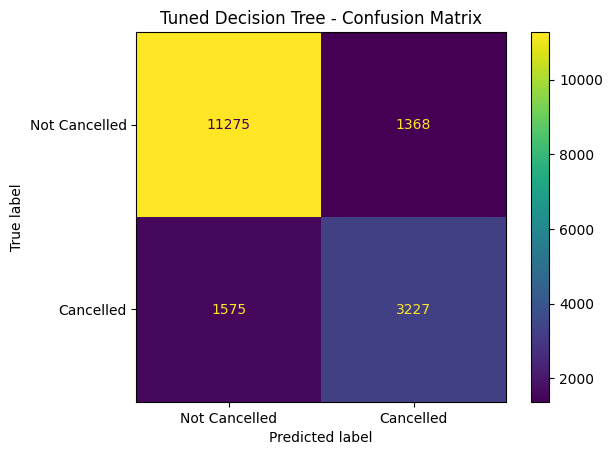

In [15]:
# ============================================================
# 14. TUNED CONFUSION MATRIX
# ============================================================

cm_tuned = confusion_matrix(
    y_test,
    tuned_test_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=[
        'Not Cancelled',
        'Cancelled'
    ]
)

disp.plot()

plt.title(
    "Tuned Decision Tree - Confusion Matrix"
)

plt.show()

True Negative (11,275) = the booking was actually not cancelled, and the model correctly predicted not cancelled.

False Positive (1,368) = the booking was actually not cancelled, but the model incorrectly predicted cancelled.

False Negative (1,575) = the booking was actually cancelled, but the model incorrectly predicted not cancelled.

True Positive (3,227) = the booking was actually cancelled, and the model correctly predicted cancelled.





STEP 15 — Feature Importance

In [16]:

# 15. FEATURE IMPORTANCE


preprocessor_fitted = (
    best_tree_pipeline
    .named_steps['preprocess']
)

tree_fitted = (
    best_tree_pipeline
    .named_steps['model']
)

feature_names = (
    preprocessor_fitted
    .get_feature_names_out()
)

importance_df = pd.DataFrame({

    'Feature': feature_names,

    'Importance':
        tree_fitted.feature_importances_

})

importance_df = (
    importance_df
    .sort_values(
        'Importance',
        ascending=False
    )
)

display(
    importance_df.head(20)
)

,Feature,Importance
74,cat__country_PRT,0.178009
0,num__lead_time,0.135789
13,num__total_of_special_requests,0.123939
90,cat__market_segment_Online TA,0.075053
12,num__required_car_parking_spaces,0.067387
188,cat__agent_9,0.051873
1,num__arrival_date_year,0.049670
11,num__adr,0.030856
107,cat__deposit_type_Non Refund,0.030766
2,num__arrival_date_week_number,0.029403


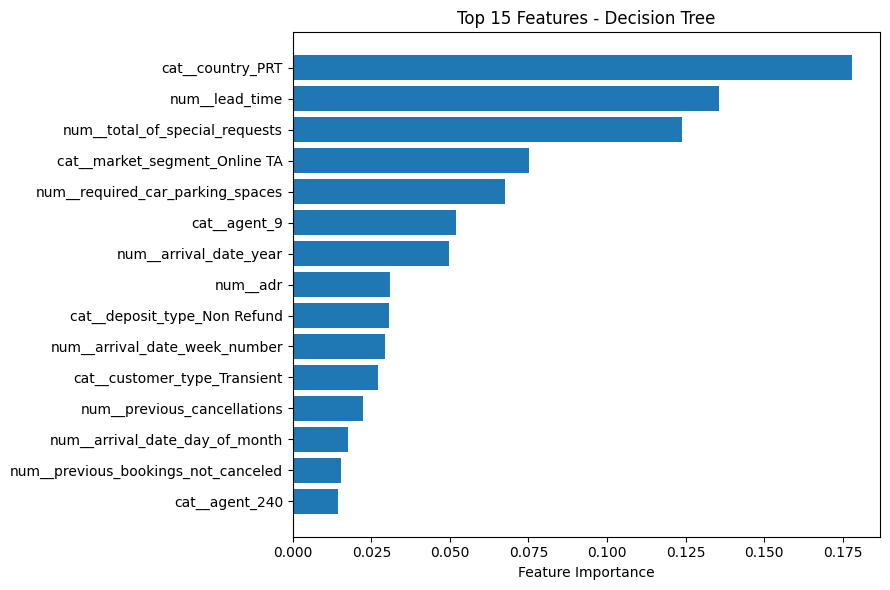

In [17]:
top_features = importance_df.head(15)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['Importance'][::-1]
)

plt.xlabel("Feature Importance")

plt.title(
    "Top 15 Features - Decision Tree"
)

plt.tight_layout()

plt.show()

STEP 16 — Visualize the top of the tree

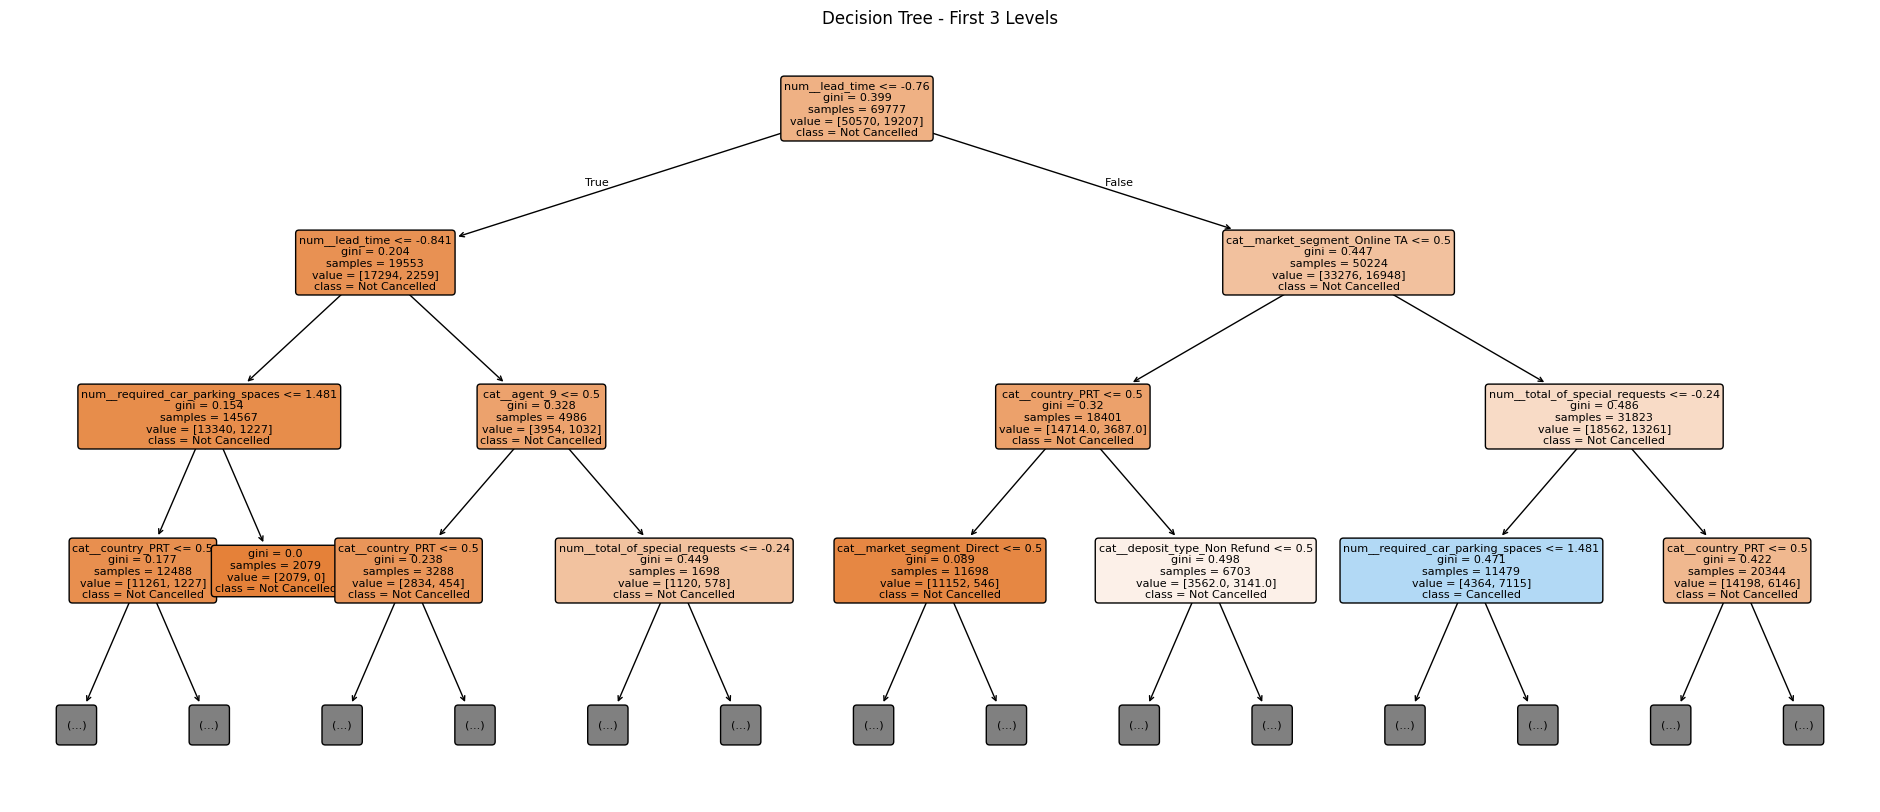

In [18]:
# ============================================================
# 16. VISUALIZE DECISION TREE
# ============================================================

plt.figure(figsize=(24, 10))

plot_tree(
    tree_fitted,
    feature_names=feature_names,
    class_names=[
        'Not Cancelled',
        'Cancelled'
    ],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title(
    "Decision Tree - First 3 Levels"
)

plt.show()

samples is the number of training observations reaching that node.

value shows how many observations of each class are present in the node, essentially the distribution of non-cancelled versus cancelled examples.

class is the class the tree would predict at that node, such as Not Cancelled or Cancelled


STEP 17 — Save your model

In [19]:

# 17. SAVE TUNED DECISION TREE


model_path = (
    MODEL_DIR /
    'decision_tree_tuned.joblib'
)

joblib.dump(
    best_tree_pipeline,
    model_path
)

print(
    "Decision Tree saved to:"
)

print(model_path)

Decision Tree saved to:
/content/drive/MyDrive/hotel-booking-cancellation/models/decision_tree_tuned.joblib


STEP 18 — Save your results

In [20]:
# ============================================================
# 18. SAVE RESULTS
# ============================================================

comparison.to_csv(
    REPORT_DIR /
    'decision_tree_comparison.csv',
    index=False
)

importance_df.to_csv(
    REPORT_DIR /
    'decision_tree_feature_importance.csv',
    index=False
)

print(
    "Decision Tree results saved."
)

Decision Tree results saved.


Metric	Simple meaning	What it answers	In your hotel cancellation project
Accuracy	Overall percentage of correct predictions	“How often was the model correct?”	Correctly predicted cancelled + not-cancelled bookings out of all bookings


Precision	Of all bookings predicted as cancelled, how many really cancelled	“When the model says cancelled, how often is it right?”	High precision = fewer false alarms


Recall	Of all bookings that actually cancelled, how many the model found	“How many real cancellations did we catch?”	High recall = fewer missed cancellations


F1-score	Balance between precision and recall	“How good is the model when both false alarms and missed cancellations matter?”	Useful because your target is imbalanced


ROC-AUC	Measures how well the model separates cancelled from not-cancelled across thresholds	“How well can the model distinguish the two classes?”	Closer to 1 is better; 0.5 is around random


Confusion Matrix	Shows counts of correct and incorrect prediction types	“Exactly where did the model make mistakes?”	Gives TN, FP, FN, TP




The easiest way to remember them is:
- Accuracy = overall correctness
- Precision = when I predict cancellation, am I usually right?
- Recall = did I catch most actual cancellations?
- F1 = balance of precision + recall
- ROC-AUC = overall ability to separate the two classes

f they ask why stratified sampling, say:

“Because the target classes were imbalanced, with about 27.5% cancelled and 72.5% not cancelled, so stratification preserved that class ratio in both train and test sets